1. Solicitando dados de concorrência com mecanismo de Failover...
Tentando servidor: https://overpass-api.de/api/interpreter...
-> Falha neste servidor. Erro: HTTPSConnectionPool(host='overpass-api.de', port=443): Read timed out. (read timeout=45). Tentando próximo da lista...
Tentando servidor: https://overpass.kumi.systems/api/interpreter...
-> Falha neste servidor. Erro: HTTPSConnectionPool(host='overpass.kumi.systems', port=443): Read timed out. (read timeout=45). Tentando próximo da lista...
Tentando servidor: https://overpass.nchc.org.tw/api/interpreter...
-> Falha neste servidor. Erro: HTTPSConnectionPool(host='overpass.nchc.org.tw', port=443): Max retries exceeded with url: /api/interpreter (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x788c4b5620d0>: Failed to resolve 'overpass.nchc.org.tw' ([Errno -2] Name or service not known)")). Tentando próximo da lista...
Tentando servidor: https://lz4.overpass-api.de/api/interpreter...
-> Sucesso usando 

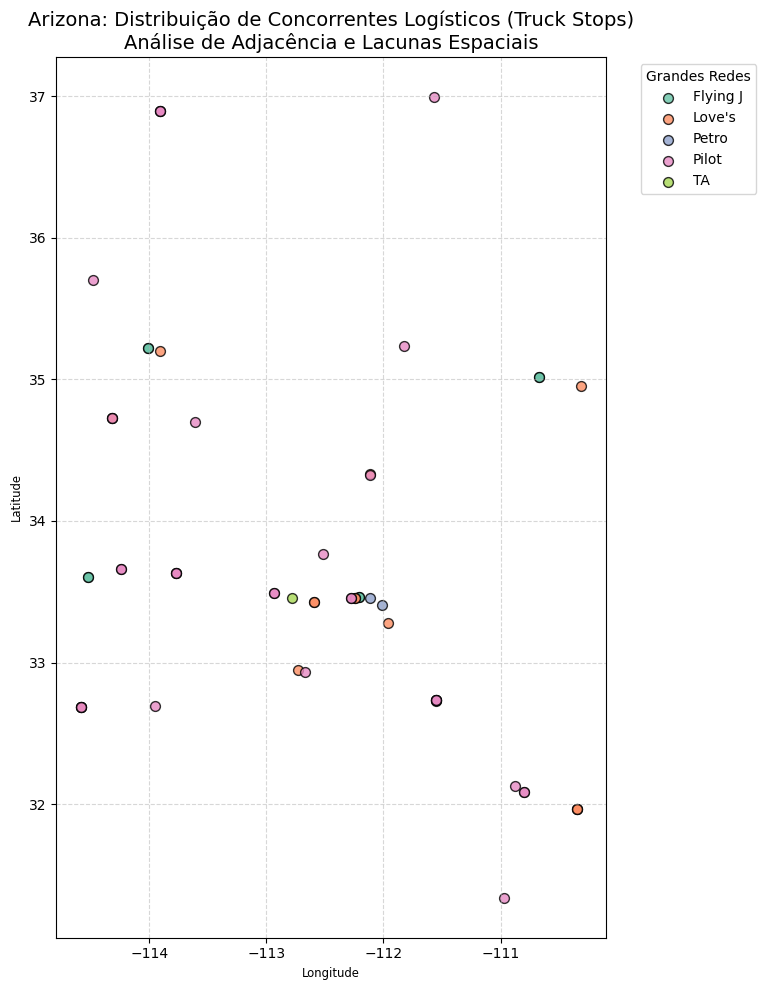

,name,brand,diesel,hgv,lat,lon,geometry
0,Love's,Love's,yes,no,32.944013,-112.733305,POINT (-112.7333 32.94401)
1,Flying J,Flying J,yes,yes,33.460910,-112.205449,POINT (-112.20545 33.46091)
2,Pilot,Pilot,yes,yes,33.633570,-113.768048,POINT (-113.76805 33.63357)
3,Pilot,Pilot,yes,yes,33.633759,-113.768818,POINT (-113.76882 33.63376)
4,Pilot,Pilot,yes,no,33.633943,-113.768020,POINT (-113.76802 33.63394)


In [ ]:
import requests
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import warnings
warnings.filterwarnings('ignore')

# 1. List of Public Servidors from Overpass (Failover)
servidores_overpass = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
    "https://overpass.nchc.org.tw/api/interpreter",
    "https://lz4.overpass-api.de/api/interpreter"
]

# Searching only big competitors on truck stops
overpass_query = """
[out:json][timeout:120];
area["name"="Arizona"]["boundary"="administrative"]->.searchArea;
(
  node["amenity"="fuel"]["brand"~"Love's|Pilot|TravelCenter|Flying J|TA|TA Express|Petro"](area.searchArea);
  way["amenity"="fuel"]["brand"~"Love's|Pilot|TravelCenter|Flying J|TA|TA Express|Petro"](area.searchArea);
);
out center;
"""

headers = {'User-Agent': 'KND_Fuels_Competitor_Analysis/1.0'}

sucesso = False
elementos = []

print("1. Solicitando dados de concorrência com mecanismo de Failover...")
for url in servidores_overpass:
    try:
        print(f"Tentando servidor: {url}...")
        response = requests.post(url, data={'data': overpass_query}, headers=headers, timeout=45)
        response.raise_for_status()
        dados = response.json()
        elementos = dados.get('elements', [])
        print(f"-> Sucesso usando o servidor: {url}!")
        sucesso = True
        break
    except Exception as e:
        print(f"-> Falha neste servidor. Erro: {e}. Tentando próximo da lista...")

if sucesso:
    print(f"\nTotal de {len(elementos)} estabelecimentos mapeados com sucesso.")

    # This code gives me 59 points, but I needed to score 11 points using data obtained manually. Always is importante verify the data.

    # 2. Manual for Extraction, Sanitization, and Strict Typing
    registros = []
    for el in elementos:
        lat = el.get('lat') if el.get('type') == 'node' else el.get('center', {}).get('lat')
        lon = el.get('lon') if el.get('type') == 'node' else el.get('center', {}).get('lon')

        if lat and lon:
            tags = el.get('tags', {})
            registros.append({
                'name': str(tags.get('name', 'N/A')),
                'brand': str(tags.get('brand', 'Desconhecido')),
                'diesel': str(tags.get('fuel:diesel', 'yes')),
                'hgv': str(tags.get('hgv', 'yes')),
                'lat': float(lat),
                'lon': float(lon),
                'geometry': Point(lon, lat)
            })

    # GeoDataFrame
    gdf_final = gpd.GeoDataFrame(registros, crs="EPSG:4326")

    # 3. Exportantion for Shapefile
    nome_shp = "competidores_truckstops_az.shp"
    gdf_export = gdf_final.copy()
    gdf_export[['name', 'brand', 'diesel', 'hgv', 'geometry']].to_file(nome_shp, driver='ESRI Shapefile')
    print(f"\n✅ Shapefile '{nome_shp}' gerado e salvo com sucesso!")

    # 4. Visualization
    print("\n2. Gerando mapa de calor de distribuição para análise de lacunas (vazios comerciais)...")
    fig, ax = plt.subplots(figsize=(10, 10))

    gdf_final.plot(
        ax=ax,
        column='brand',
        legend=True,
        cmap='Set2',
        markersize=50,
        edgecolor='black',
        alpha=0.8,
        legend_kwds={'bbox_to_anchor': (1.05, 1), 'loc': 'upper left', 'title': 'Grandes Redes'}
    )

    ax.set_title("Arizona: Distribuição de Concorrentes Logísticos (Truck Stops)\nAnálise de Adjacência e Lacunas Espaciais", fontsize=14)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

    display(gdf_final.head())
else:
    print("\n❌ Todos os servidores do Overpass falharam temporariamente devido a alta demanda global. Por favor, tente executar novamente em alguns instantes.") #text on portuguese sinalizing a error in case of bug